In [2]:
import numpy as np
import pandas as pd
import re
import nltk
import string

In [3]:
import pandas as pd

df = pd.read_json("hf://datasets/ru-dataset/tg-ru-engagement/channel_data_clean.json")

In [4]:
df.head(10)

,id,date,text,links,has_links,has_media,media_type,views,forwards,reply_to
0,42952,2026-07-21 18:42:01+00:00,Новая версия Telegram перегревает iPhone и зав...,[],False,True,photo,44198,277,NaN
1,42953,2026-07-21 18:58:01+00:00,В России хотят разрешить ставить на учёт машин...,[],False,False,NaN,42846,201,NaN
2,42954,2026-07-21 19:43:01+00:00,Суд обязал девушку выплатить 10 тысяч рублей м...,[],False,True,video,51331,606,NaN
3,42955,2026-07-21 20:28:01+00:00,"Франция стала первой страной Евросоюза, приняв...",[],False,False,NaN,48342,225,NaN
4,42956,2026-07-21 22:05:14+00:00,Завтракающие каждый день на 28% реже покупают ...,[],False,False,NaN,48507,481,NaN
5,42957,2026-07-22 04:09:49+00:00,Логистические центры Wildberries в Краснодаре ...,[],False,False,NaN,48382,357,NaN
6,42958,2026-07-22 05:05:17+00:00,"ЦБ, скорее всего, не станет менять ключевую ст...",[],False,False,NaN,46038,49,NaN
7,42959,2026-07-22 05:26:01+00:00,Мошенники начали разводить пользователей прини...,[],False,True,photo,48143,182,NaN
8,42962,2026-07-22 06:02:01+00:00,Россиян предупредили о новой схеме мошенничест...,[],False,False,NaN,41716,265,NaN
9,42963,2026-07-22 06:33:01+00:00,Заморозить цены на продукты предложили в Госду...,[],False,False,NaN,41195,147,NaN


In [5]:
##Нижний регистр.
df['text_lower']  = df['text'].str.lower()
df['text_lower'].head()

0    новая версия telegram перегревает iphone и зав...
1    в россии хотят разрешить ставить на учёт машин...
2    суд обязал девушку выплатить 10 тысяч рублей м...
3    франция стала первой страной евросоюза, приняв...
4    завтракающие каждый день на 28% реже покупают ...
Name: text_lower, dtype: str

In [6]:
#Удаление пунктуации    
df['text_lower'] = df['text_lower'].str.replace('[^\w\s]','')
df['text_lower'].head()

<>:2: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
<>:2: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
C:\Users\psitn\AppData\Local\Temp\ipykernel_22732\1806836331.py:2: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
  df['text_lower'] = df['text_lower'].str.replace('[^\w\s]','')


0    новая версия telegram перегревает iphone и зав...
1    в россии хотят разрешить ставить на учёт машин...
2    суд обязал девушку выплатить 10 тысяч рублей м...
3    франция стала первой страной евросоюза, приняв...
4    завтракающие каждый день на 28% реже покупают ...
Name: text_lower, dtype: str

In [7]:
#nltk.download('stopwords')
from nltk.corpus import stopwords
print(stopwords.words('russian'))

['и', 'в', 'во', 'не', 'что', 'он', 'на', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она', 'так', 'его', 'но', 'да', 'ты', 'к', 'у', 'же', 'вы', 'за', 'бы', 'по', 'только', 'ее', 'мне', 'было', 'вот', 'от', 'меня', 'еще', 'нет', 'о', 'из', 'ему', 'теперь', 'когда', 'даже', 'ну', 'вдруг', 'ли', 'если', 'уже', 'или', 'ни', 'быть', 'был', 'него', 'до', 'вас', 'нибудь', 'опять', 'уж', 'вам', 'ведь', 'там', 'потом', 'себя', 'ничего', 'ей', 'может', 'они', 'тут', 'где', 'есть', 'надо', 'ней', 'для', 'мы', 'тебя', 'их', 'чем', 'была', 'сам', 'чтоб', 'без', 'будто', 'чего', 'раз', 'тоже', 'себе', 'под', 'будет', 'ж', 'тогда', 'кто', 'этот', 'того', 'потому', 'этого', 'какой', 'совсем', 'ним', 'здесь', 'этом', 'один', 'почти', 'мой', 'тем', 'чтобы', 'нее', 'сейчас', 'были', 'куда', 'зачем', 'всех', 'никогда', 'можно', 'при', 'наконец', 'два', 'об', 'другой', 'хоть', 'после', 'над', 'больше', 'тот', 'через', 'эти', 'нас', 'про', 'всего', 'них', 'какая', 'много', 'разве', 'три', 'эту', 'моя', 'впр

In [8]:
#Удаление стоп-слов
#Импорт стоп-слов из бибилиотеки nltk
from nltk.corpus import stopwords
STOPWORDS = set(stopwords.words('russian'))
# функция, удаляющая стопслова из текстов

def stopwords(text):
    return " ".join([word for word in str(text).split() if word not in STOPWORDS])
# Применим функцию удаления стоп-слов
df["text_lower"] = df["text_lower"].apply(stopwords)
df["text_lower"].head()

0    новая версия telegram перегревает iphone завал...
1    россии хотят разрешить ставить учёт машины, ко...
2    суд обязал девушку выплатить 10 тысяч рублей м...
3    франция стала первой страной евросоюза, приняв...
4    завтракающие каждый день 28% реже покупают вещ...
Name: text_lower, dtype: str

In [9]:
#Удаление высокочастотных слов
from collections import Counter
cnt = Counter()
for text in df["text_lower"].values:
    for word in text.split():
        cnt[word] += 1
        
cnt.most_common(20)

[('—', 49086),
 ('@bezposhady', 34194),
 ('подписаться', 28977),
 ('топор', 28370),
 ('👉', 28264),
 ('+18.', 24860),
 ('это', 8848),
 ('россии', 6778),
 ('из-за', 5762),
 ('тысяч', 4641),
 ('рублей', 4175),
 ('рублей.', 3978),
 ('также', 3920),
 ('могут', 3621),
 ('которые', 3494),
 ('который', 3373),
 ('года', 3210),
 ('её', 3093),
 ('время', 3061),
 ('•', 2943)]

In [10]:
#удаление часто встречающиеся слов в корпусе при помощи tf-idf
# Удаление самых частотных слов
freq = set([w for (w, wc) in cnt.most_common(10)])
# функция удаления слов
def freqwords(text):
    return " ".join([word for word in str(text).split() if word not 
in freq])
# применение функции
df["text_lower"] = df["text_lower"].apply(freqwords)
df["text_lower"].head()

0    новая версия telegram перегревает iphone завал...
1    хотят разрешить ставить учёт машины, которые ч...
2    суд обязал девушку выплатить 10 рублей мужчине...
3    франция стала первой страной евросоюза, приняв...
4    завтракающие каждый день 28% реже покупают вещ...
Name: text_lower, dtype: str

In [11]:
#Удаление низкочастотных слов
freq = pd.Series(' '.join(df['text_lower']).split()).value_counts()[-10:] # 10 rare words
freq = list(freq.index)
df['text_lower'] = df['text_lower'].apply(lambda x: " ".join(x for x in x.split() if x not in freq))
df['text_lower'].head()

0    новая версия telegram перегревает iphone завал...
1    хотят разрешить ставить учёт машины, которые ч...
2    суд обязал девушку выплатить 10 рублей мужчине...
3    франция стала первой страной евросоюза, приняв...
4    завтракающие каждый день 28% реже покупают вещ...
Name: text_lower, dtype: str

In [12]:
# Удаление эмодзи
def emoji(string):
    emoji_pattern = re.compile("["
                           u"\U0001F600-\U0001F64F"  # emoticons
                           u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                           u"\U0001F680-\U0001F6FF"  # transport & map symbols
                           u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                           u"\U00002702-\U000027B0"
                           u"\U000024C2-\U0001F251"
                           "]+", flags=re.UNICODE)
    return emoji_pattern.sub(r'', string)
#passing the emoji function to 'text_rare'
df['text_lower'] = df['text_lower'].apply(emoji)

In [13]:
#Удаление цифр  
df['text_lower'] = df['text_lower'].str.replace(r'\d+', '', regex=True) 
df['text_lower'].head()

0    новая версия telegram перегревает iphone завал...
1    хотят разрешить ставить учёт машины, которые ч...
2    суд обязал девушку выплатить  рублей мужчине, ...
3    франция стала первой страной евросоюза, приняв...
4    завтракающие каждый день % реже покупают вещи ...
Name: text_lower, dtype: str

In [14]:
print(repr(df['text_lower'][3]))

'франция стала первой страной евросоюза, принявшей закон запрете соцсетей детей  лет. документ вступает силу  сентября. входа соцсети пользователям нужно подтверждать возраст, платформы будут обязаны блокировать доступ несовершеннолетним. исключение сделано видео youtube переписок мессенджерах.'


In [15]:
#Удаление URL
# Function for url's
def remove_urls(text):
    url_pattern = re.compile(r'https?://\S+|www\.\S+')
    return url_pattern.sub(r'', text)

In [16]:
#Удаление HTML-тегов
from bs4 import BeautifulSoup
#Function for removing html
def html(text):
    return BeautifulSoup(text, "lxml").text

# Passing the function to 'text_rare'
df['text_lower'] = df['text_lower'].apply(html)

C:\Users\psitn\AppData\Local\Temp\ipykernel_22732\1129559862.py:5: MarkupResemblesLocatorWarning: The input passed in on this line looks more like a URL than HTML or XML.

If you meant to use Beautiful Soup to parse the web page found at a certain URL, then something has gone wrong. You should use an Python package like 'requests' to fetch the content behind the URL. Once you have the content as a string, you can feed that string into Beautiful Soup.

However, if you want to parse some data that happens to look like a URL, then nothing has gone wrong: you are using Beautiful Soup correctly, and this warning is spurious and can be filtered. To make this warning go away, run this code before calling the BeautifulSoup constructor:

    from bs4 import MarkupResemblesLocatorWarning
    import warnings

    warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
    
  return BeautifulSoup(text, "lxml").text


In [17]:
#Токенизация
def tokenization(text):
    text = re.split('\W+', text)
    return text
# Passing the function to 'text_rare' and store into'text_token'
df['ready'] = df['text_lower'].apply(lambda x: tokenization(x.lower()))
df[['ready']].head()

<>:3: SyntaxWarning: "\W" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\W"? A raw string is also an option.
<>:3: SyntaxWarning: "\W" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\W"? A raw string is also an option.
C:\Users\psitn\AppData\Local\Temp\ipykernel_22732\3393277205.py:3: SyntaxWarning: "\W" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\W"? A raw string is also an option.
  text = re.split('\W+', text)


,ready
0,"[новая, версия, telegram, перегревает, iphone,..."
1,"[хотят, разрешить, ставить, учёт, машины, кото..."
2,"[суд, обязал, девушку, выплатить, рублей, мужч..."
3,"[франция, стала, первой, страной, евросоюза, п..."
4,"[завтракающие, каждый, день, реже, покупают, в..."


In [18]:
#Можно выполнить при помощи NLTK. Заодно проведем лемматизацию
from pymorphy3 import MorphAnalyzer
from nltk import sent_tokenize, word_tokenize, regexp_tokenize

def tokenize_lemmas(sent, pat=r"(?u)\b\w\w+\b", morph=MorphAnalyzer()):
    return [morph.parse(tok)[0].normal_form 
            for tok in regexp_tokenize(sent, pat)]
df["text_lower"] = df["text_lower"].map(lambda x: " ".join(tokenize_lemmas(x)))
df[['text_lower']].head()

,text_lower
0,новый версия telegram перегревать iphone завал...
1,хотеть разрешить ставить учёт машина который ч...
2,суд обязать девушка выплатить рубль мужчина ко...
3,франция стать первый страна евросоюз принять з...
4,завтракать каждый день редкий покупать вещь сп...


In [19]:
import torch
from transformers import AutoModelForSequenceClassification
from transformers import BertTokenizerFast

tokenizer = BertTokenizerFast.from_pretrained('blanchefort/rubert-base-cased-sentiment')
model = AutoModelForSequenceClassification.from_pretrained('blanchefort/rubert-base-cased-sentiment', return_dict=True)


def predict(text):
    inputs = tokenizer(text, max_length=512, padding=True, truncation=True, return_tensors='pt')
    outputs = model(**inputs)
    predicted = torch.nn.functional.softmax(outputs.logits, dim=1)
    predicted = torch.argmax(predicted, dim=1).numpy()
    return predicted

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [20]:
import sqlite3
connection = sqlite3.connect('C:/Users/psitn/OneDrive/Desktop/python/preproc/etym.db')

In [21]:
cursor = connection.cursor()

In [22]:
cursor.execute('SELECT * FROM links')
users = cursor.fetchall()

In [23]:
for user in users:
    print(user)

# Закрываем соединение
connection.close()

(623, 523, 1, 1, 'a', 2)
(624, 523, 1, 2, 'i', 1)
(625, 524, 1, 1, 'а', 1)
(626, 525, 0, 1, 'не', 0)
(627, 526, 0, 1, 'ажур', 1)
(628, 526, 0, 2, 'бат', 1)
(629, 527, 0, 1, 'базь', 0)
(630, 529, 0, 1, 'бе', 2)
(631, 530, 1, 1, 'а́збука', 0)
(632, 530, 1, 2, 'алфа́віт', 0)
(633, 531, 0, 1, 'абажу́р', 0)
(634, 531, 0, 2, 'сади́ти', 0)
(635, 531, 1, 1, 'о́бца́с', 0)
(636, 533, 0, 1, 'бир', 1)
(637, 534, 0, 1, 'аби́', 0)
(638, 534, 0, 2, 'що', 0)
(639, 535, 0, 1, 'а', 1)
(640, 535, 0, 2, 'бо', 0)
(641, 535, 1, 1, 'а́льбо́', 0)
(642, 536, 0, 1, 'мовня́', 0)
(643, 538, 0, 1, 'абажу́р', 0)
(644, 538, 0, 2, 'рони́ти', 0)
(645, 539, 0, 1, 'абажу́р', 0)
(646, 540, 0, 1, 'пекти́', 0)
(647, 540, 0, 2, 'при', 0)
(648, 541, 0, 1, 'бруку', 0)
(649, 542, 0, 1, 'абажу́р', 0)
(650, 542, 0, 2, 'ла́ва', 0)
(651, 542, 0, 3, 'свій', 0)
(652, 542, 0, 4, 'себе́', 0)
(653, 543, 0, 1, 'абажу́р', 0)
(654, 544, 0, 1, 'абажу́р', 0)
(655, 546, 0, 1, 'а́бза́ц', 0)
(656, 548, 0, 1, 'а', 2)
(657, 549, 0, 1, 'абажур', 

In [24]:
from nltk import FreqDist
import matplotlib.pyplot as plt

In [25]:
# Создание частотного распределения
text = FreqDist(df["text_lower"])
fdist = FreqDist(text)

In [26]:
# Анализ частот
print(fdist.most_common(10))    # 10 самых частых слов

[('дарить сертификат сумма также кешбэк любимый категория оформление бесплатный дебетовый карта мтс оформить дебетовый карта мтс вечный бесплатный обслуживание ссылка получить гарантировать подарок выгодный условие сертификат номинал выбор ozon золотой яблоко пятёрочка магнит до кешбэк каждый месяц любимый категория кешбэк продуктовый магазин рынок вечно бесплатный обслуживание платёж перевод до кешбэк ежемесячно забрать сертификат течение день момент выпуск карта совершить любой покупка получить сертификат выбор оформить карта', 30), ('банк выйти новый уровень дебетовый карта выпустить аромакарта вкус шоколад клубника кокос сосна мятый банк переставать удивлять выходить лимитировать серия карта аромат выбор карта приятно радовать бонус кэшбэкома вкусно пахнуть преимущество карта помимо крутой аромат кэшбэк рубль покупка партнёр любимый категория обслуживание пополнение перевод бесплатный снятие наличный банкомат банк комиссия оплата жку интернет учёба садик карта действовать страна вы

In [27]:
print(fdist['карта'])            # Частота конкретного слова

0


In [28]:
print(fdist.hapaxes()[:10])     # Слова, встречающиеся один раз

['новый версия telegram перегревать iphone заваливать пользователь ложный уведомление нажатие который открываться устройство быстрый разряжаться остановить зарядка перегрев баг встречаться стабильный бета версия ios пока временно помогать полный переустановка мессенджер', 'хотеть разрешить ставить учёт машина который числиться угнать база интерпол купить законно соответствовать законопроект внести госдума принять владелец смочь зарегистрировать автомобиль специальный процедура тот поздний оказаться розыск', 'суд обязать девушка выплатить рубль мужчина который облизывать её обувь московский автобус осень прошлое год мужчина лечь нога пассажирка начать трогать её нога согласие облизывать обувь снять всё видео выложить сеть публикация мужчина просить удалить ролик получить отказ обратиться суд который встать сторона посчитать публикация нарушить личный неимущественный право девушка намерить обжаловать решение видео написать другой женщина жаловаться домогательство человек', 'франция стать

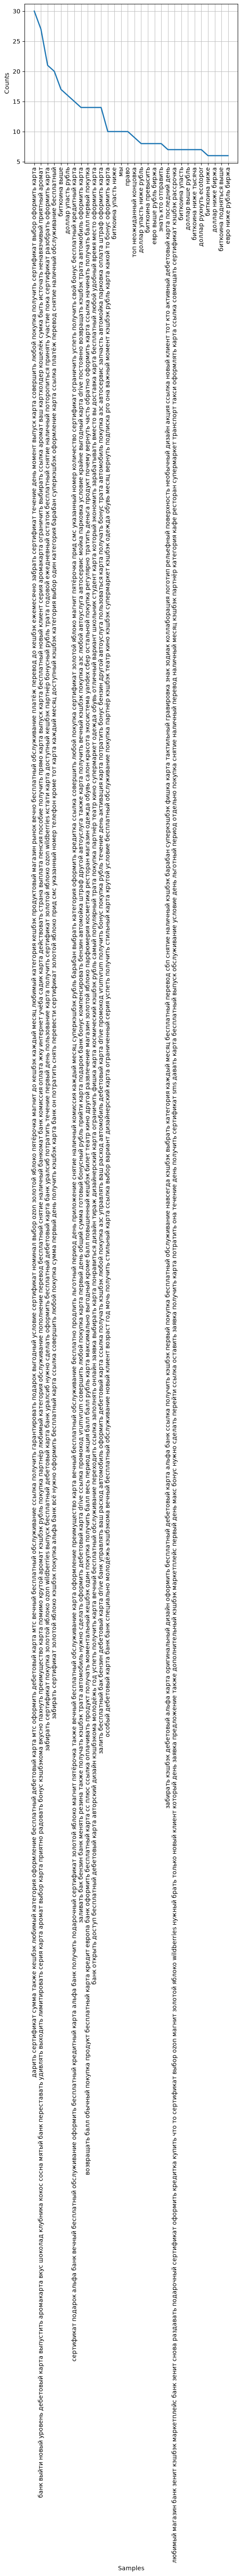

<Axes: xlabel='Samples', ylabel='Counts'>

In [29]:
# Визуализация
fdist.plot(30, cumulative=False)

In [30]:
plt.show()

In [31]:
df[["text_lower"]].to_csv("preprocessed_tg.csv", index=False, encoding="utf-8-sig")

In [32]:
df[["text_lower"]].to_csv("preprocessed_tg.csv", index=False, encoding="utf-8-sig")

import os
print(os.getcwd())
print(os.path.abspath("preprocessed_tg.csv"))

C:\Users\psitn\OneDrive\Desktop\python\sitnikova_polina
C:\Users\psitn\OneDrive\Desktop\python\sitnikova_polina\preprocessed_tg.csv
